In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('evaluated_result.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

# ── group num_of_neighbors into bins of 5 (1-5, 6-10, 11-15, …) ──────────────
BIN_SIZE = 5
max_neighbors = int(df['num_of_neighbors'].max())
bin_edges = list(range(0, max_neighbors + BIN_SIZE, BIN_SIZE))
NEIGHBOR_GROUPS = [f'{lo + 1}-{lo + BIN_SIZE}' for lo in bin_edges[:-1]]
df['neighbor_group'] = pd.cut(
    df['num_of_neighbors'], bins=bin_edges, labels=NEIGHBOR_GROUPS, right=True
)

def weighted_group_mean(frame: pd.DataFrame, value_col: str) -> pd.Series:
    """Mean of value_col per neighbour_group, weighted by num_of_neighbors."""
    def _wavg(g):
        mask = g[value_col].notna()
        if not mask.any():
            return np.nan
        return np.average(g.loc[mask, value_col], weights=g.loc[mask, 'num_of_neighbors'])
    return frame.groupby('neighbor_group', observed=True)[[value_col, 'num_of_neighbors']].apply(_wavg).reindex(NEIGHBOR_GROUPS)

print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)


945 rows  |  0 generation errors


,node_id,mag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,llm_accuracy,llm_coherence,llm_language,num_of_neighbors,is_error,neighbor_group
0,1089,2953793718,We deal with the \textit{selective classificat...,We propose a new method for training neural ne...,0.3721,0.1137,0.1927,0.8602,0.8143,0.8366,2,8,8,69,False,66-70
1,1102,2958885478,Traditional 3D Convolutional Neural Networks (...,"In this paper, we propose a novel 3D convoluti...",0.3027,0.1254,0.1958,0.8823,0.8232,0.8518,4,8,8,50,False,46-50
2,1121,2964693852,Various formal languages have been proposed in...,We present a new approach to the specification...,0.3279,0.0773,0.1967,0.8655,0.8561,0.8608,6,8,8,37,False,36-40


In [2]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour-count group (e.g. 1-5, 6-10, …)."""
    values = [series.get(g, np.nan) for g in NEIGHBOR_GROUPS]
    x = np.arange(len(NEIGHBOR_GROUPS))

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(x, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(NEIGHBOR_GROUPS, rotation=45, ha='right')
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()


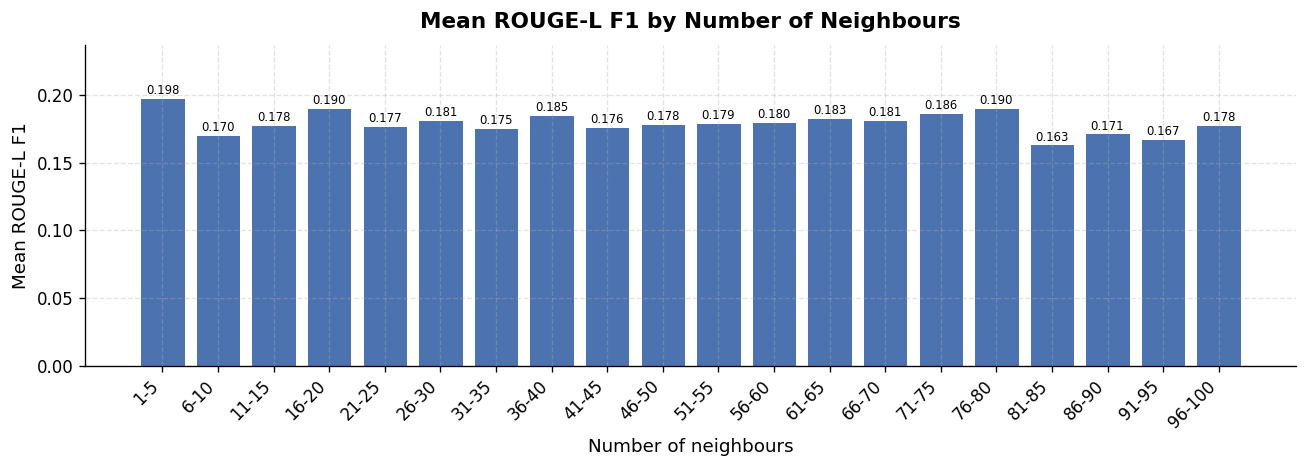

In [3]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = weighted_group_mean(df, 'rougeL_f')
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

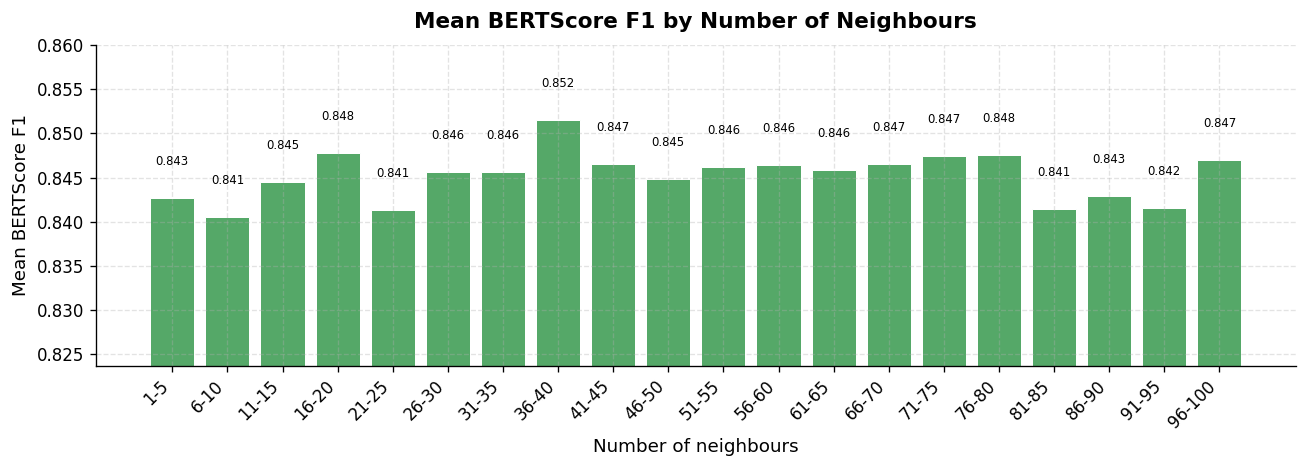

In [4]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = weighted_group_mean(df, 'bertscore_f1')
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

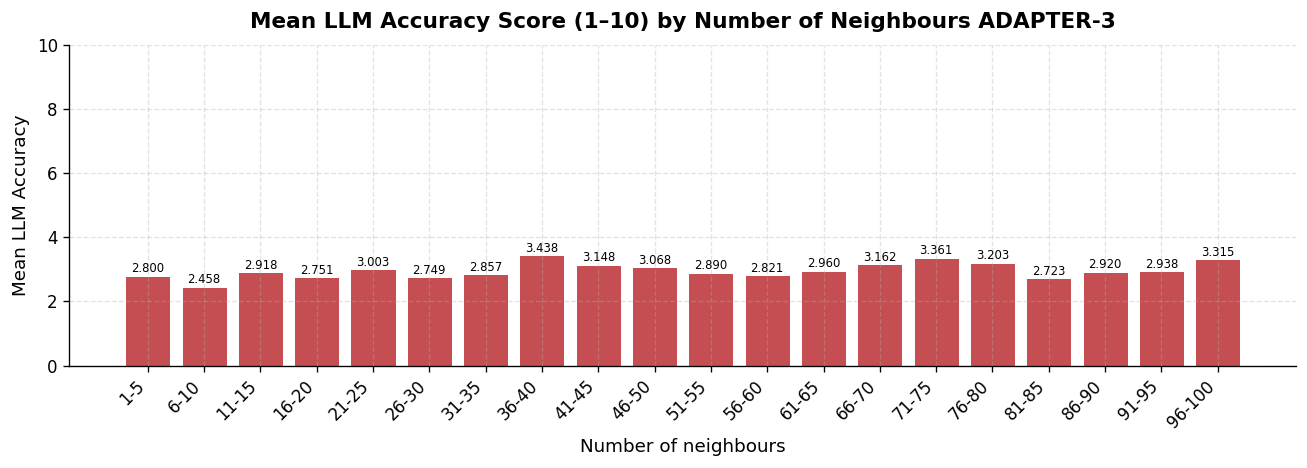

2.9746031746031747
3.0


In [5]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = weighted_group_mean(df, 'llm_accuracy')
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

print(df['llm_accuracy'].mean())
print(df['llm_accuracy'].median())

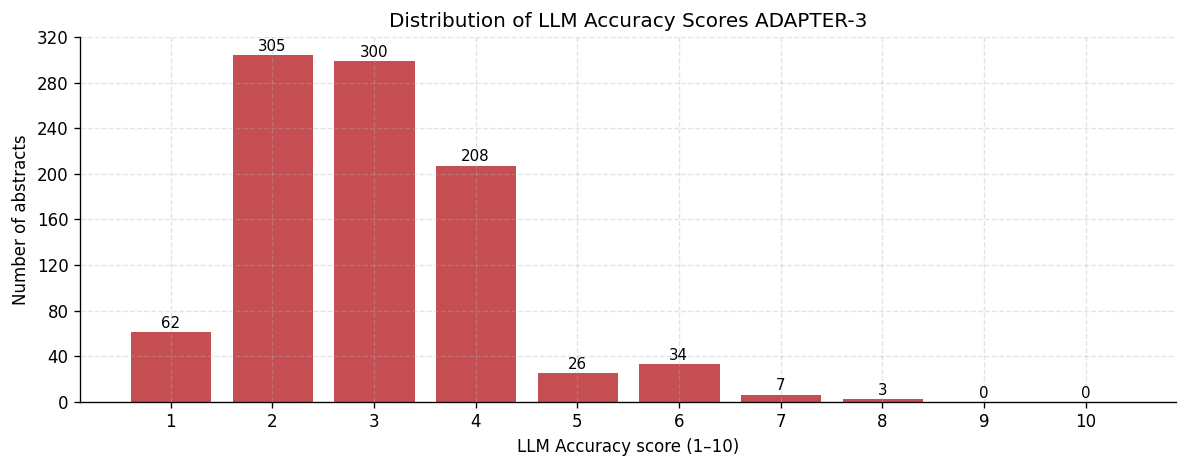

llm_accuracy
1      62
2     305
3     300
4     208
5      26
6      34
7       7
8       3
9       0
10      0
Name: count, dtype: int64

In [6]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_accuracy'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color='#C44E52',
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM Accuracy Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

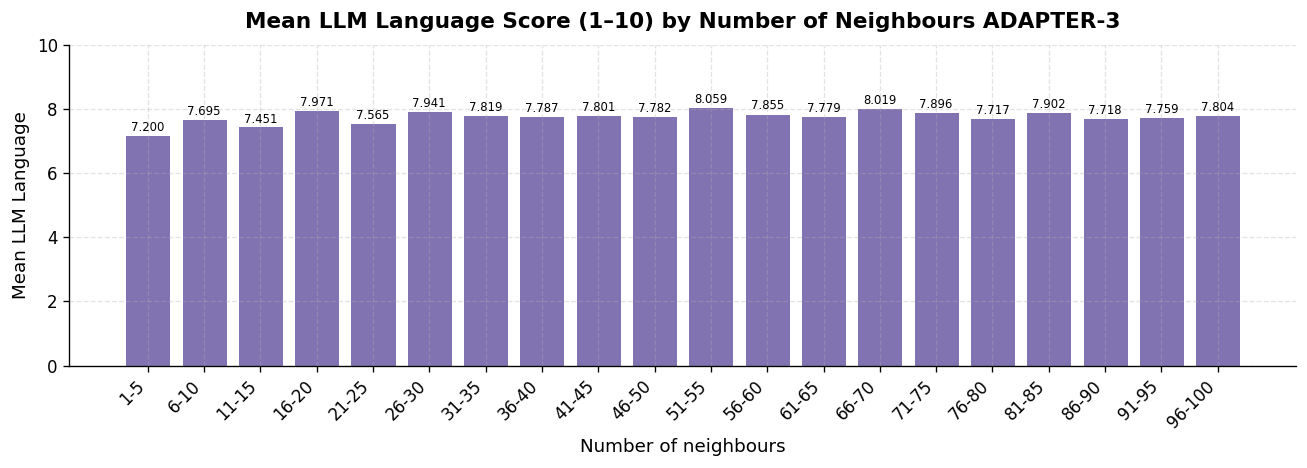

In [7]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = weighted_group_mean(df, 'llm_language')
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

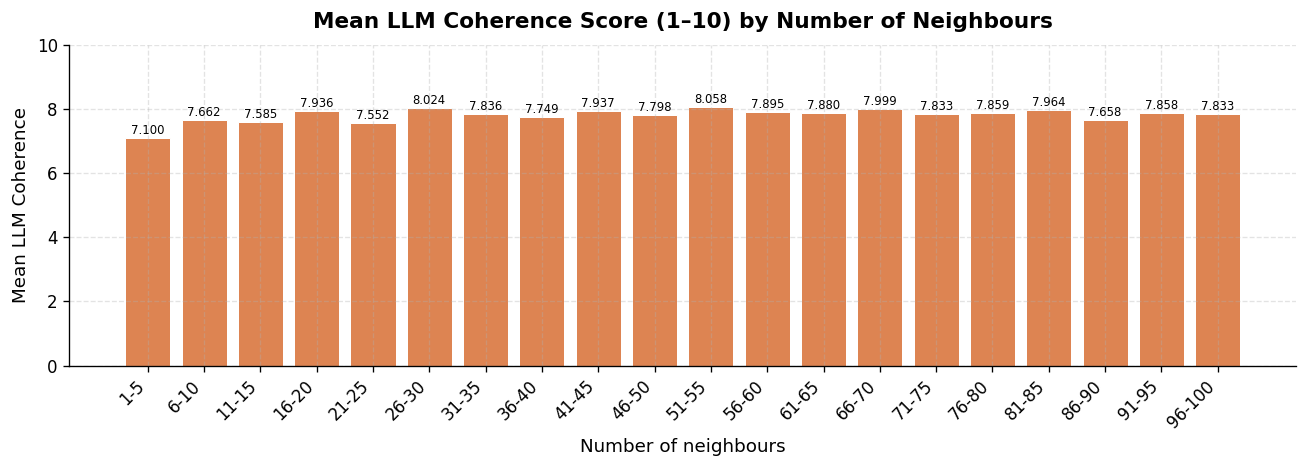

In [8]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = weighted_group_mean(df, 'llm_coherence')
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

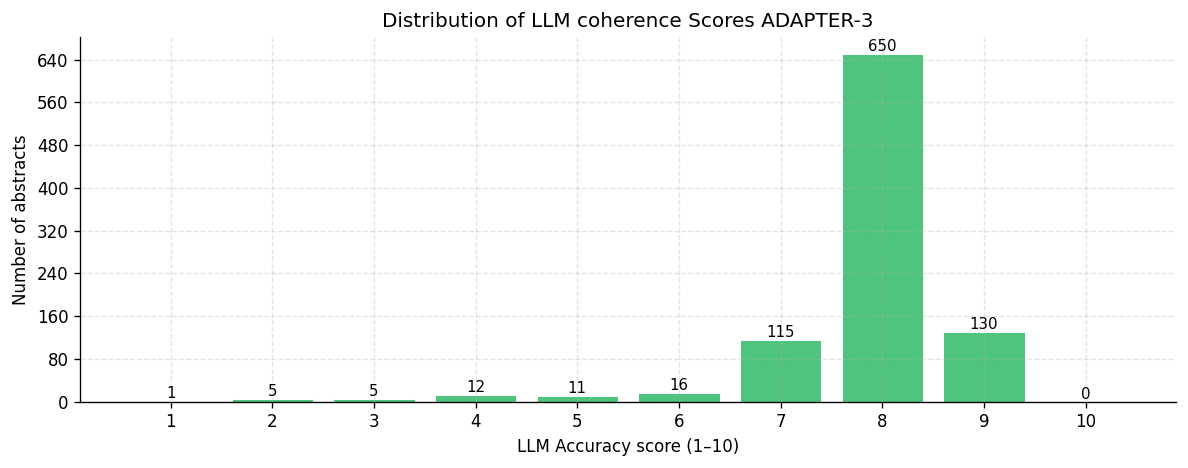

llm_coherence
1       1
2       5
3       5
4      12
5      11
6      16
7     115
8     650
9     130
10      0
Name: count, dtype: int64

In [9]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_coherence'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color="#4EC47F",
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM coherence Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

In [10]:
# ── Mean llm_accuracy excluding low-coherence (1, 2) samples ─────────────────
filtered_df = df[~df['llm_coherence'].isin([1, 2])]

print(f'Excluded {len(df) - len(filtered_df)} rows with llm_coherence in [1, 2]')
print(f'Mean llm_accuracy (all rows):      {df["llm_accuracy"].mean():.4f}')
print(f'Mean llm_accuracy (excluding 1,2): {filtered_df["llm_accuracy"].mean():.4f}')


Excluded 6 rows with llm_coherence in [1, 2]
Mean llm_accuracy (all rows):      2.9746
Mean llm_accuracy (excluding 1,2): 2.9840


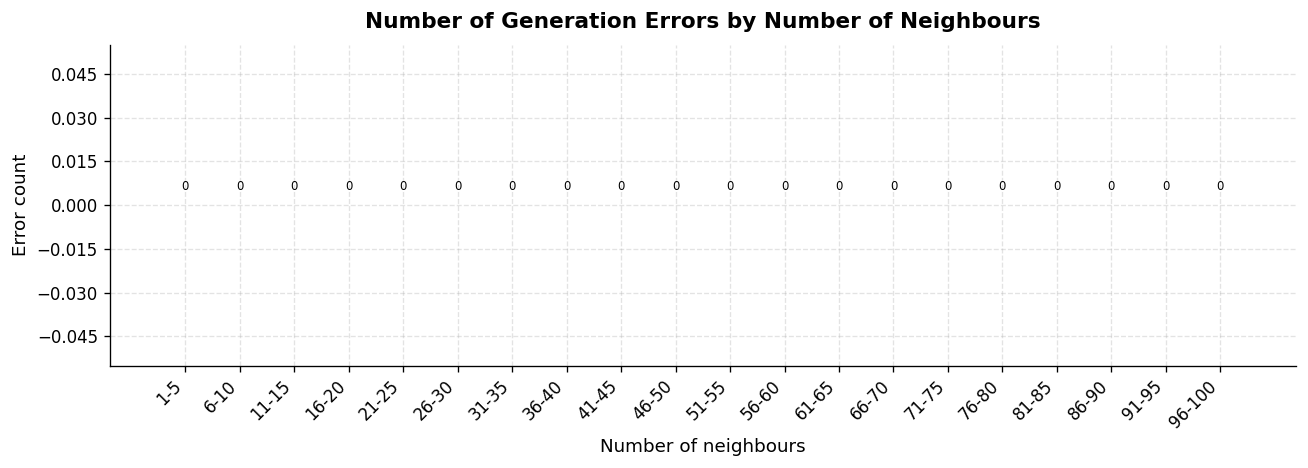

In [11]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('neighbor_group', observed=True).size().reindex(NEIGHBOR_GROUPS, fill_value=0)
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

In [12]:
# ── 5 examples each of llm_coherence score 1 and 2 ───────────────────────────
low_coherence_sample = (
    df[df['llm_coherence'].isin([1, 2])]
    .sort_values('llm_coherence')
    .groupby('llm_coherence', sort=True)
    .apply(lambda g: g.head(5))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_coherence']]
)

pd.set_option('display.max_colwidth', 2000)
low_coherence_sample


/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_81212/3088027966.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(5))


,node_id,original_abstract,generated_abstract,llm_coherence
0,6299,"Blockchain has come a long way: a system that was initially proposed specifically for cryptocurrencies is now being adapted and adopted as a general-purpose transactional system. A blockchain is also a distributed system, and as such it shares some similarities with distributed database systems. Existing works that compare blockchains and distributed database systems focus mainly on high-level properties, such as security and throughput. They stop short of showing how the underlying design choices contribute to the overall differences. Our paper is to fill this important gap. In this paper, we perform a twin study of blockchains and distributed database systems as two types of transactional systems. We propose a taxonomy that helps illustrate their similarities and differences. In particular, we compare the systems along four dimensions: replication, concurrency, storage, and sharding. We discuss how the design choices have been driven by the system's goals: blockchain's goal is security, whereas the distributed database's goal is performance. We then conduct an extensive and in-depth performance study on two blockchains, namely Quorum and Hyperledger Fabric, and three distributed databases, namely CockroachDB, TiDB and etcd. We demonstrate how the different design choices in the four dimensions lead to different performance. In addition, we show that for most workloads, blockchain's performance is still lagging far behind that of a distributed database. However, the gap is not as significant as previously reported, and under high contention or constrained workloads, blockchains and databases are even comparable. Our work provides a framework for exploring the design space of hybrid database-blockchain systems.","Blockchain is a new paradigm for distributed systems that has been gaining popularity in recent years. It is a decentralized, distributed ledger that is maintained by a network of nodes. The nodes are not trusted, and they are not controlled by a central authority. The nodes are connected to each other through a peer-to-peer network. The nodes are not connected to each other through the Internet. The nodes are connected through a peer-to-peer protocol. The nodes are connected by a peer-to-peer protocol that is based on the Internet. The nodes communicate with each other through a peer to peer protocol. The nodes communicate with other nodes through a peer to peer network. The nodes communicate with the other nodes through a peer-to-peer connection. The nodes communicate with one another through a peer-to-peer communication protocol. The nodes communicate through a peer-to-peer communications protocol. The nodes communicate using a peer-to-peer communications network. The nodes communicate through the peer-to-peer communications network using a peer-to-peer communication network. The nodes communicate using the peer-to-peer communications protocol using a peer-to-peer network connection. The nodes communicate using peer-to-peer communications network connection. The nodes are connected using a peer-to-peer connection using a peer-to-peer protocol using a peer-to peer network connection. The nodes use a peer-to-peer connection to communicate with each other. The nodes use a network connection to communicate with each. The nodes use a connection to communicate with each of the other nodes. The nodes use a communication network to communicate with each of other nodes. The nodes communicate with a network connection to communicate. The nodes communicate with another node using",1
1,27177,"On the January 22th 2019, Airbus launched a quantum computing challenge to solve a set of problems relevant for the aircraft life cycle (this https URL). The challenge consists of a set of 5 problems that ranges from design to deployment of aircraft. This work addresses the 5th problem. The formulation exploits an Integer programming framework with a linear objective func

In [13]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_81212/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,41033,"Egocentric vision (a.k.a. first-person vision - FPV) applications have thrived over the past few years, thanks to the availability of affordable wearable cameras and large annotated datasets. The position of the wearable camera (usually mounted on the head) allows recording exactly what the camera wearers have in front of them, in particular hands and manipulated objects. This intrinsic advantage enables the study of the hands from multiple perspectives: localizing hands and their parts within the images; understanding what actions and activities the hands are involved in; and developing human-computer interfaces that rely on hand gestures. In this survey, we review the literature that focuses on the hands using egocentric vision, categorizing the existing approaches into: localization (where are the hands or part of them?); interpretation (what are the hands doing?); and application (e.g., systems that used egocentric hand cues for solving a specific problem). Moreover, a list of the most prominent datasets with hand-based annotations is provided.","We present a novel approach to the problem of human action recognition in RGB-D videos. Our approach is based on the observation that the human body is a rigid object, and that the motion of the body is a combination of rigid and non-rigid motions. We propose to model the human body as a rigid object, and to use the rigid motion of the body to infer the non-rigid motion of the body parts. We propose to use a combination of a rigid motion model and a non-rigid motion model to infer the motion of the body parts from the motion of the body. We propose to use the rigid motion model to infer the non-rigidity of the body parts, and to use the non-rigidity to infer the motion of each body part. We propose to use an ensemble of rigid motion models to infer the non-rigion of the body parts, to infer the motion of body parts, and to infer the motion of individual body parts. We propose a novel approach to the human action recognition problem, which is based on the observation of the human body as a combination of rigid and flexible motions. We propose to use this observation to infer the motion of a body part from the motion of the whole body. We propose to infer the motion of an individual body part from the motion and the non-rigidity. We propose to use these observations to infer the motion of all body parts from the motion and the rigidity of the whole body.",1
1,127698,"Online advertising has been a long-standing concern for user privacy and overall web experience. Several techniques have been proposed to block ads, mostly based on filter-lists and manually-written rules. While a typical ad blocker relies on manually-curated block lists, these inevitably get out-of-date, thus compromising the ultimate utility of this ad blocking approach. In this paper we present Percival, a browser-embedded, lightweight, deep learning-powered ad blocker. Percival embeds itself within the browser's image rendering pipeline, which makes it possible to intercept every image obtained during page execution and to perform blocking based on applying machine learning for image classification to flag potential ads. Our implementation inside both Chromium and Brave browsers shows only a minor rendering performance overhead of 4.55%, demonstrating the feasibility of deploying traditionally heavy models (i.e. deep neural networks) inside the critical path of the rendering engine of a browser. We show that our image-based ad blocker can replicate EasyList rules with an accuracy of 96.76%. To show the versatility of the Percival's approach we present case studies that demonstrate that Percival 1) does surprisingly well on ads in languages other than English; 2) Percival also performs well on blocking first-party Facebook ads, which have presented issues for other ad blockers. Percival proves that image-based perceptual ad blocking is an attractive 

In [14]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

KeyError: "None of [Index(['cat_wrong_domain', 'cat_multi_paper_contamination',\n       'cat_wrong_methodology', 'cat_wrong_task', 'cat_too_generic',\n       'cat_truncated_incomplete'],\n      dtype='object')] are in the [columns]"

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


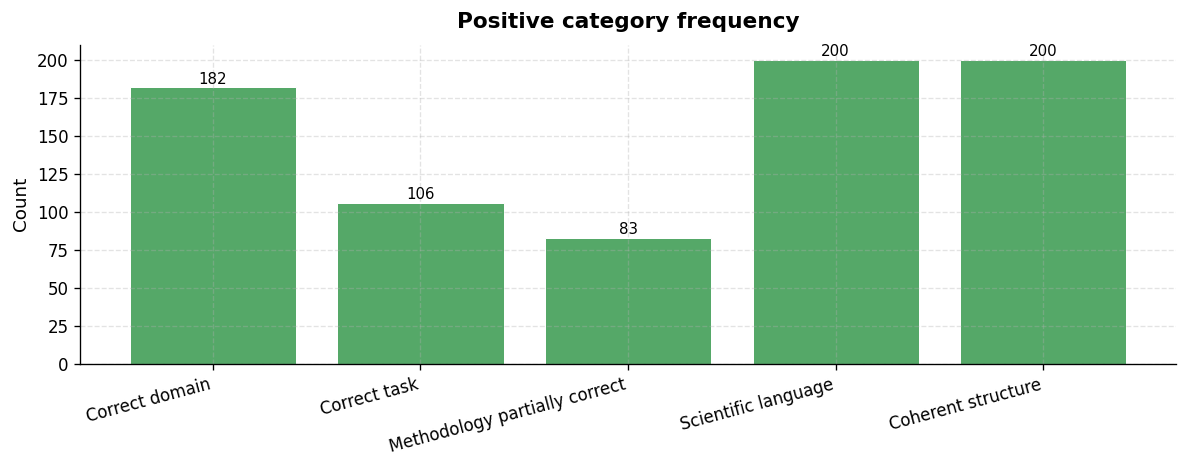

In [ ]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()